# **KNN Classification - Diabetes Dataset**
Target: `diabetes` (0 = No, 1 = Yes)

**KNN (K-Nearest Neighbors) Classifier:** to classify a new patient, it finds the `k` most similar patients in the training data and takes a vote. The predicted probability of diabetes = share of those `k` neighbors who have diabetes.

Hyperparameters tuned with `GridSearchCV` (5-fold, stratified):
- `n_neighbors` (k): small k = follows noise (overfit), big k = too smooth (underfit)
- `weights`: `uniform` (all neighbors equal) or `distance` (closer neighbors count more)
- `p`: distance type (1 = Manhattan, 2 = Euclidean)

**Imbalance:** only ~9% of patients are diabetic. In a vote, the majority class (no diabetes) usually wins, so KNN tends to miss diabetic patients. We handle this with a stratified split, **undersampling** the majority class, and **threshold tuning**, and we judge with recall / F1 / ROC-AUC (not accuracy).

> KNN works on distances, so features must be scaled. Our data is already scaled (`diabetes_after_preprocessing.csv`, 96,030 rows).

### 1. Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

### 2. Load data, check imbalance, stratified split

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
x = df.drop('diabetes', axis=1)
y = df['diabetes']
print(df.shape, '| Diabetic %:', round(y.mean() * 100, 2))

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print('Diabetic % train:', round(y_train.mean() * 100, 2), '| test:', round(y_test.mean() * 100, 2))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(96030, 12) | Diabetic %: 8.83
Diabetic % train: 8.83 | test: 8.83


### 3. Tune KNN (GridSearchCV)
Scored with **ROC-AUC** (does not depend on the 0.5 threshold, not fooled by imbalance). `algorithm='kd_tree'` makes the neighbor search fast on 77k rows.

In [3]:
%%time
knn = KNeighborsClassifier(algorithm='kd_tree', n_jobs=1)

param_grid = {
    'n_neighbors': [5, 11, 21, 31, 51, 101],
    'weights': ['uniform', 'distance'],
    'p': [1, 2],
}

grid = GridSearchCV(knn, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(x_train, y_train)

print('Best Params :', grid.best_params_)
print('Best CV AUC :', round(grid.best_score_, 4))


Best Params : {'n_neighbors': 101, 'p': 1, 'weights': 'uniform'}
Best CV AUC : 0.9673
CPU times: total: 12.3 s
Wall time: 3min 55s


### 4. k vs ROC-AUC
Very small k follows noise (CV AUC is low). The score rises as k grows because more neighbors vote, so the vote is more reliable. In this run the score is still rising slowly at the biggest k in the grid (101), so the best k is at the edge of the grid and a bigger k (for example 151 or 201) might help a little more.

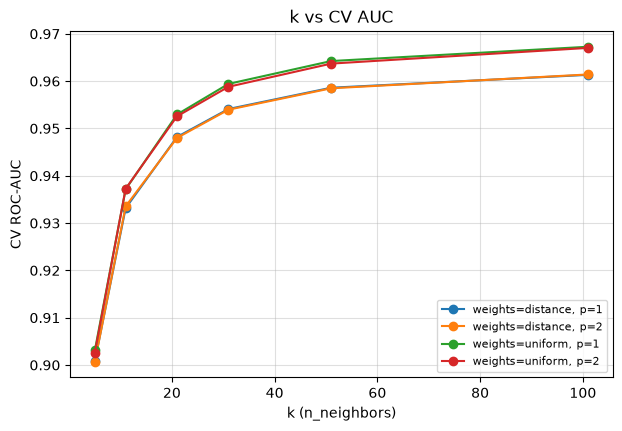

In [4]:
res = pd.DataFrame(grid.cv_results_)
res['k'] = res['param_n_neighbors'].astype(int)

plt.figure(figsize=(7, 4.5))
for (w, p), r in res.groupby(['param_weights', 'param_p']):
    r = r.sort_values('k')
    plt.plot(r['k'], r['mean_test_score'], 'o-', label=f'weights={w}, p={p}')
plt.xlabel('k (n_neighbors)'); plt.ylabel('CV ROC-AUC'); plt.title('k vs CV AUC')
plt.legend(fontsize=8); plt.grid(alpha=0.4); plt.show()

### 5. Handle imbalance (3 strategies)
1. **Plain** KNN, threshold 0.5
2. **Undersampling:** keep all diabetic patients, but only an equal number of random non-diabetic patients in the training data (the neighbors are then 50% / 50%)
3. **Plain + tuned threshold:** choose the probability cut-off that gives the best F1 (found from CV predictions on the training data only)

In [5]:
%%time
best_knn = grid.best_estimator_

# 1. plain
plain = clone(best_knn).fit(x_train, y_train)
p_plain = plain.predict_proba(x_test)[:, 1]

# 2. undersampling the majority class (training data only)
idx_pos = y_train[y_train == 1].index
idx_neg = y_train[y_train == 0].sample(n=len(idx_pos), random_state=42).index
idx_bal = idx_pos.union(idx_neg)
under = clone(best_knn).fit(x_train.loc[idx_bal], y_train.loc[idx_bal])
p_under = under.predict_proba(x_test)[:, 1]
print('Undersampled train size:', len(idx_bal), '(was', len(x_train), ')')

# 3. tuned threshold from out-of-fold probabilities
oof = cross_val_predict(clone(best_knn), x_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1_curve)]
print('Best threshold (max CV F1):', round(best_thr, 3))

def scores(name, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'Strategy': name, 'Threshold': round(threshold, 3), 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'ROC_AUC': roc_auc_score(y_test, proba)}

pd.DataFrame([scores('1. Plain (0.5)', p_plain, 0.5),
              scores('2. Undersampling (0.5)', p_under, 0.5),
              scores('3. Plain + tuned threshold', p_plain, best_thr)]).set_index('Strategy').round(4)

Undersampled train size: 13572 (was 76824 )
Best threshold (max CV F1): 0.287
CPU times: total: 57.8 s
Wall time: 1min 6s


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
1. Plain (0.5),0.500,0.9571,0.9955,0.5171,0.6806,0.9640
2. Undersampling (0.5),0.500,0.8869,0.4322,0.8950,0.5829,0.9633
3. Plain + tuned threshold,0.287,0.9595,0.8576,0.6498,0.7393,0.9640


### 6. Threshold table (precision vs recall trade-off)
Lower threshold = find more diabetic patients (higher recall) but more false alarms.

In [6]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (p_plain >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'Missed diabetic': int(((pred == 0) & (y_test == 1)).sum()),
                 'False alarms': int(((pred == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows).set_index('Threshold').round(3)

,Precision,Recall,F1,Missed diabetic,False alarms
Threshold,,,,,
0.5,0.995,0.517,0.681,819,4
0.4,0.972,0.563,0.713,741,28
0.3,0.892,0.630,0.739,627,130
0.2,0.697,0.739,0.717,442,546
0.1,0.466,0.878,0.609,207,1709


### 7. Final model: plain KNN + tuned threshold
Change `final_threshold` if you prefer more recall.

              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17510
    Diabetes       0.86      0.65      0.74      1696

    accuracy                           0.96     19206
   macro avg       0.91      0.82      0.86     19206
weighted avg       0.96      0.96      0.96     19206



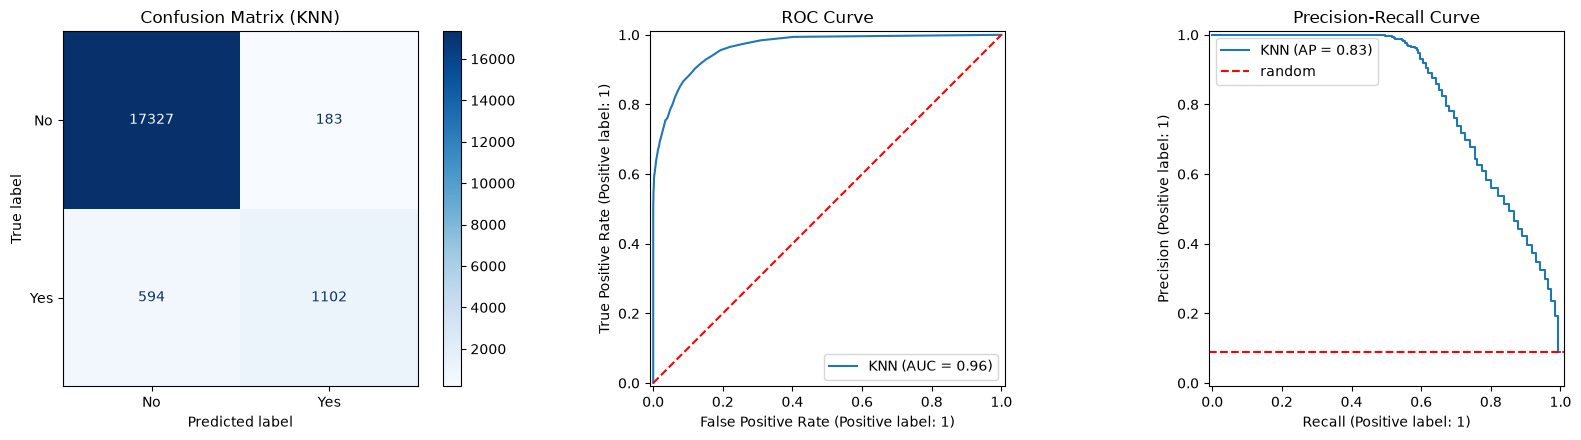

In [7]:
final_threshold = best_thr
final_pred = (p_plain >= final_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['No', 'Yes'], cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix (KNN)')
RocCurveDisplay.from_predictions(y_test, p_plain, name='KNN', ax=ax[1]); ax[1].plot([0, 1], [0, 1], 'r--')
ax[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, p_plain, name='KNN', ax=ax[2])
ax[2].axhline(y_test.mean(), color='r', ls='--', label='random'); ax[2].legend(); ax[2].set_title('Precision-Recall Curve')
plt.tight_layout(); plt.show()

### 8. Compare with Logistic Regression and Naive Bayes (reference)
Same train/test split, best parameters from the earlier notebooks.

In [8]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

cont_cols = ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
bin_cols = [c for c in x.columns if c not in cont_cols]

logit = LogisticRegression(solver='liblinear', C=0.316, penalty='l2').fit(x_train, y_train)
nbayes = Pipeline([('prep', ColumnTransformer([('cont', KBinsDiscretizer(n_bins=20, encode='ordinal', strategy='uniform'), cont_cols),
                                               ('bin', 'passthrough', bin_cols)])),
                   ('model', CategoricalNB(alpha=0.01, min_categories=20))]).fit(x_train, y_train)

compare = pd.DataFrame([
    scores('KNN (+ tuned threshold)', p_plain, final_threshold),
    scores('Logistic Regression (0.5)', logit.predict_proba(x_test)[:, 1], 0.5),
    scores('Naive Bayes - binned (0.5)', nbayes.predict_proba(x_test)[:, 1], 0.5),
]).set_index('Strategy')
compare.round(4)

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
KNN (+ tuned threshold),0.287,0.9595,0.8576,0.6498,0.7393,0.9640
Logistic Regression (0.5),0.500,0.9581,0.8626,0.6256,0.7252,0.9593
Naive Bayes - binned (0.5),0.500,0.9607,0.8147,0.7182,0.7634,0.9708


### 9. Save the model (.pkl)
The model is trained on all data. The threshold is saved with it. (KNN stores the training data, so the file is bigger than for other models.)

In [9]:
final_knn = clone(best_knn).fit(x, y)

package = {'model': final_knn, 'threshold': float(final_threshold), 'features': list(x.columns)}
joblib.dump(package, 'knn_diabetes_model.pkl', compress=3)
pd.DataFrame(grid.cv_results_).drop(columns='params').to_csv('knn_tuning_results.csv', index=False)

#Load and predict
pkg = joblib.load('knn_diabetes_model.pkl')
proba = pkg['model'].predict_proba(x_test.iloc[:5][pkg['features']])[:, 1]
print('Diabetes probability:', proba.round(3))
print('Prediction          :', (proba >= pkg['threshold']).astype(int))
print('Actual              :', y_test.iloc[:5].values)

Diabetes probability: [0.04  0.    0.    0.228 0.   ]
Prediction          : [0 0 0 0 0]
Actual              : [0 0 0 1 0]


(These 5 rows were also in the training data of the final model. This cell only checks that the saved file loads and predicts. The honest accuracy is in the test tables above.)

### 10. Download (Google Colab only)

In [10]:
try:
    from google.colab import files
    files.download('knn_diabetes_model.pkl')
    files.download('knn_tuning_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
